In [2]:
# 1 — Configuration. Point to the SAVED aggregation run, not a clustering run.
from pathlib import Path
from datetime import datetime, timezone
import hashlib, importlib.util, importlib.metadata, json, sys, time
import numpy as np
import pandas as pd
from scipy import sparse
from IPython.display import display

ROOT = Path.home() / 'scgpt-cna'
PARENT_RUN = ROOT / 'aggregation_context/results/20261123T213545773600Z_full'
RESUME_RUN = None  # Path('...printed context_sweep run folder...')
POOL_SIZES = [1, 10]  # [1, 5, 10] is allowed if you later want a separate sensitivity run.
LENGTHS = [600, 900, 1200, 2400, 4800]
REFERENCE_LENGTH = 1200
DEVICE = 'cpu'  # 'cuda' only in a GPU allocation with CUDA-enabled PyTorch.
N_THREADS = 4
BOOTSTRAPS = 2000
REUSE_PARENT = True
UNIT_IDS = None  # None = all parent units. Or an explicit list of saved unit_id strings.
MODEL = ROOT / 'models/whole-human'
HELPER = ROOT / 'notebooks/scgpt_session/scgpt_session.py'
PREPROCESS = ROOT / 'sanity_check/reference_4068d67/scgpt/preprocess.py'
METHODS = ['GEP', 'MVC', 'gene_mean_plus_offset']
GROUPS = ['all', '1 UMI', '2–4 UMIs', '5+ UMIs']

def sha(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for chunk in iter(lambda: f.read(8*1024**2), b''): h.update(chunk)
    return h.hexdigest()
def seed(*parts):
    return int(hashlib.sha256('|'.join(map(str, parts)).encode()).hexdigest()[:16], 16)
def import_exact(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    m = importlib.util.module_from_spec(spec); sys.modules[name] = m
    spec.loader.exec_module(m)
    return m
def group_umi(x):
    return np.select([x == 1, x <= 4], ['1 UMI', '2–4 UMIs'], default='5+ UMIs')
def write_json(path, obj):
    path = Path(path); tmp = path.with_name(path.name+'.tmp')
    tmp.write_text(json.dumps(obj, indent=2)); tmp.replace(path)

if RESUME_RUN is not None:
    RUN_DIR = Path(RESUME_RUN).expanduser().resolve()
    saved = json.loads((RUN_DIR/'run_manifest.json').read_text())
    for key in ['POOL_SIZES','LENGTHS','REFERENCE_LENGTH','BOOTSTRAPS','REUSE_PARENT','UNIT_IDS','DEVICE']:
        globals()[key] = saved[key]
    PARENT_RUN = Path(saved['PARENT_RUN'])
    MODEL = Path(saved['MODEL']); HELPER = Path(saved['HELPER']); PREPROCESS = Path(saved['PREPROCESS'])
else:
    RUN_DIR = ROOT/'context_sweep/results'/datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')

PARENT_RUN = PARENT_RUN.expanduser().resolve()
if not (PARENT_RUN/'tasks_prepared.json').is_file():
    candidates = sorted((ROOT/'aggregation_context/results').glob('*/tasks_prepared.json'))
    print('Prepared aggregation runs:\n'+'\n'.join(str(p.parent) for p in candidates))
    raise FileNotFoundError('Set PARENT_RUN to a prepared aggregation run listed above.')
parent = json.loads((PARENT_RUN/'run_manifest.json').read_text())
assert set(POOL_SIZES) <= set(parent['POOL_SIZES'])
assert POOL_SIZES == sorted(set(POOL_SIZES)) and LENGTHS == sorted(set(LENGTHS))
assert REFERENCE_LENGTH in LENGTHS and DEVICE in {'cpu','cuda'}
assert parent['config']['n_bins'] == 51 and parent['config']['max_seq_len'] == 1200
units = pd.read_csv(PARENT_RUN/'evaluation_units.csv', dtype={'cluster':str})
if UNIT_IDS is not None:
    assert set(UNIT_IDS) <= set(units.unit_id)
    units = units.loc[units.unit_id.isin(UNIT_IDS)].copy()
assert len(units) and units.unit_id.is_unique
POOL_SEEDS = parent['POOL_SEEDS']; MASK_SEEDS = parent['MASK_SEEDS']
print('Parent:', PARENT_RUN, '\nNew output:', RUN_DIR)
print('Pool sizes:', POOL_SIZES, '| budgets:', LENGTHS, '| masks:', MASK_SEEDS)
display(units[[c for c in ['unit_id','sample_id','tissue','cluster','n_reference_families','n_evaluation_families','evidence_status'] if c in units]])


Parent: /home/akash1/scgpt-cna/aggregation_context/results/20261123T213545773600Z_full 
New output: /home/akash1/scgpt-cna/context_sweep/results/20261128T181334828041Z
Pool sizes: [1, 10] | budgets: [600, 900, 1200, 2400, 4800] | masks: [42, 43, 44, 45]


,unit_id,sample_id,tissue,cluster,n_reference_families,n_evaluation_families,evidence_status
0,C3N-00148-01__leiden_r0.25__stratum00,C3N-00148-01,Kidney,0,32,32,full
1,C3N-00148-01__leiden_r0.25__stratum01,C3N-00148-01,Kidney,1,32,32,full
2,C3N-01798-01__leiden_r0.25__stratum00,C3N-01798-01,Brain,0,32,32,full
3,C3N-01798-01__leiden_r0.25__stratum01,C3N-01798-01,Brain,1,32,32,full
4,CENSUS_PROXIMAL_TUBULE_256__one_group__stratum00,CENSUS_PROXIMAL_TUBULE_256,Kidney,0,3,3,small-cohort pilot


In [3]:
# 2 — Audit the exact saved inputs; freeze this new run's source inventory.
config = json.loads((MODEL/'args.json').read_text())
vocab = json.loads((MODEL/'vocab.json').read_text())
assert config == parent['config']
for key, path in [('checkpoint_sha256',MODEL/'best_model.pt'), ('vocab_sha256',MODEL/'vocab.json'),
                  ('helper_sha256',HELPER), ('preprocess_sha256',PREPROCESS)]:
    assert sha(path) == parent[key], f'{key} differs from the parent run.'
historical = import_exact('context_sweep_pinned_preprocess', PREPROCESS)
assert historical._digitize.__defaults__ == ('one',), 'This run requires historical upper-tie bins.'

def bins_of(row):
    return np.asarray(historical.binning(row.data.copy(), n_bins=51), dtype=float)

source_paths = [PARENT_RUN/'run_manifest.json', PARENT_RUN/'evaluation_units.csv']
for u in units.to_dict('records'):
    d = PARENT_RUN/u['unit_id']
    source_paths.append(d/'gene_tokens.npy')
    for c in POOL_SEEDS:
        source_paths += [d/f'pool_counts_seed{c}.npz', d/f'pool_metadata_seed{c}.csv',
                         d/f'frozen_tasks_seed{c}.csv.gz', d/f'context_orders_seed{c}.npz']
        source_paths += [d/f'baseline_seed{c}_k{k}.npz' for k in POOL_SIZES]
inventory = {str(p):sha(p) for p in source_paths}
versions = {p:importlib.metadata.version(p) for p in ['numpy','pandas','scipy','torch','scgpt']}
# Fail clearly rather than silently combining different inference implementations.
for p in ['torch','scgpt']:
    assert versions[p].split('+')[0] == parent['versions'][p].split('+')[0], f'{p} version changed: {versions[p]} vs {parent["versions"][p]}'
settings = {k:globals()[k] for k in ['POOL_SIZES','LENGTHS','REFERENCE_LENGTH','BOOTSTRAPS','REUSE_PARENT','UNIT_IDS','DEVICE']}
settings.update(PARENT_RUN=str(PARENT_RUN), MODEL=str(MODEL), HELPER=str(HELPER), PREPROCESS=str(PREPROCESS),
    parent_sha256=sha(PARENT_RUN/'run_manifest.json'), input_hashes=inventory, versions=versions,
    checkpoint_sha256=parent['checkpoint_sha256'], helper_sha256=parent['helper_sha256'],
    preprocess_sha256=parent['preprocess_sha256'], vocab_sha256=parent['vocab_sha256'])
if RESUME_RUN is None:
    RUN_DIR.mkdir(parents=True, exist_ok=False)
    write_json(RUN_DIR/'run_manifest.json', settings)
    units.to_csv(RUN_DIR/'evaluation_units.csv', index=False)
else:
    assert settings == saved, 'Configuration, prepared sources or package versions changed; start a separate run.'
RUN_SIGNATURE = sha(RUN_DIR/'run_manifest.json')
print('Frozen-source audit passed. Source aggregation files will not be modified.')


/home/akash1/scgpt-cna/.venv-scgpt/lib/python3.10/site-packages/scgpt/model/model.py:21: UserWarning: flash_attn is not installed
  warnings.warn("flash_attn is not installed")
/home/akash1/scgpt-cna/.venv-scgpt/lib/python3.10/site-packages/scgpt/model/multiomic_model.py:19: UserWarning: flash_attn is not installed
  warnings.warn("flash_attn is not installed")


Frozen-source audit passed. Source aggregation files will not be modified.


In [4]:
# 3 — Shared job construction, integrity checks and verified reuse of parent predictions.
# No model weights load in this cell.
def prepared(u, construction):
    d = PARENT_RUN/u['unit_id']
    matrix = sparse.load_npz(d/f'pool_counts_seed{construction}.npz').tocsr()
    genes = np.load(d/'gene_tokens.npy')
    assert matrix.has_canonical_format and matrix.shape[1] == len(genes)
    assert len(set(genes)) == len(genes) and np.all(matrix.data > 0)
    tasks = pd.read_csv(d/f'frozen_tasks_seed{construction}.csv.gz')
    tasks = tasks.loc[tasks.pool_size.isin(POOL_SIZES)].copy()
    assert not tasks.duplicated(['mask_seed','pool_row','gene_token']).any()
    assert set(tasks.mask_seed) == set(MASK_SEEDS)
    assert set(tasks.pool_size) == set(POOL_SIZES)
    orders_file = np.load(d/f'context_orders_seed{construction}.npz')
    orders = {key:orders_file[key] for key in orders_file.files}; orders_file.close()
    baselines = {}
    for k in POOL_SIZES:
        with np.load(d/f'baseline_seed{construction}_k{k}.npz') as b:
            baselines[k] = b['means'].copy()
        assert baselines[k].shape == (len(genes),) and np.isfinite(baselines[k]).all()
    return matrix, genes, tasks, orders, baselines

def make_job(matrix, genes, part, orders, means, length):
    pool_row = int(part.pool_row.iloc[0]); mask = int(part.mask_seed.iloc[0])
    row = matrix.getrow(pool_row); bb = bins_of(row)
    prefix = f'r{pool_row}_m{mask}'
    qi = np.asarray(orders[prefix+'_query_positions'], dtype=int)
    order = np.asarray(orders[prefix+'_visible_order'], dtype=int)
    np.testing.assert_array_equal(genes[row.indices[qi]], part.gene_token.to_numpy())
    np.testing.assert_array_equal(bb[qi], part.target_bin.to_numpy())
    assert len(qi) == len(set(qi)) and len(order) == len(set(order))
    np.testing.assert_array_equal(np.sort(np.r_[qi,order]), np.arange(row.nnz))
    assert length > len(qi)+1, f'{length} leaves no visible context for {len(qi)} queries.'
    vi = order[:length-1-len(qi)]
    kg = genes[row.indices[vi]]; kv = bb[vi]; qg = genes[row.indices[qi]]
    offset = float(np.mean(kv-means[row.indices[vi]]))
    baseline = means[row.indices[qi]]+offset
    h = hashlib.sha256()
    for a in [kg.astype('<i8'), kv.astype('<f8'), qg.astype('<i8')]:
        h.update(np.asarray([len(a)], dtype='<i8').tobytes()); h.update(a.tobytes())
    info = dict(unit_id=part.unit_id.iloc[0], construction_seed=int(part.construction_seed.iloc[0]),
        pool_row=pool_row, family_id=part.family_id.iloc[0], pool_size=int(part.pool_size.iloc[0]),
        mask_seed=mask, context_budget=int(length), n_detected=row.nnz, n_visible=len(vi), n_queries=len(qi),
        visible_fraction=len(vi)/row.nnz, visible_fraction_of_available=len(vi)/len(order),
        actual_tokens=1+len(vi)+len(qi), hidden_fraction=len(qi)/(len(vi)+len(qi)),
        saturated=len(vi)==len(order), visible_offset=offset, known_query_sha256=h.hexdigest())
    return (kg,kv,qg), baseline, info

def parent_block(u, construction, mask, size, length, tasks, expected_inputs):
    if not REUSE_PARENT or length not in parent['LENGTHS']: return None
    d = PARENT_RUN/u['unit_id']
    path = d/f'predictions_seed{construction}_mask{mask}.csv.gz'
    stamp_path = d/f'predictions_seed{construction}_mask{mask}.complete.json'
    inp = d/f'inference_inputs_seed{construction}_mask{mask}.csv'
    if not all(p.is_file() for p in [path,stamp_path,inp]): return None
    # This is the exact input-signature rule used by the original aggregation notebook.
    original_paths = [PARENT_RUN/'run_manifest.json', d/'gene_tokens.npy', d/f'pool_counts_seed{construction}.npz',
        d/f'frozen_tasks_seed{construction}.csv.gz', d/f'context_orders_seed{construction}.npz']
    original_paths += [d/f'baseline_seed{construction}_k{k}.npz' for k in parent['POOL_SIZES']]
    stamp = json.loads(stamp_path.read_text())
    sig = hashlib.sha256('|'.join(sha(p) for p in original_paths).encode()).hexdigest()
    assert sha(path) == stamp['sha256'] and sig == stamp['input_signature'], 'Parent inference cache failed integrity audit.'
    q = pd.read_csv(path)
    q = q.loc[q.pool_size.eq(size)&q.context_budget.eq(length)].copy()
    expected = tasks.loc[tasks.mask_seed.eq(mask)&tasks.pool_size.eq(size)].copy()
    keys = ['pool_row','gene_token']
    assert not q.duplicated(keys).any()
    check = expected.merge(q, on=keys, how='outer', suffixes=('_e','_p'), indicator=True, validate='one_to_one')
    assert check['_merge'].eq('both').all()
    for col in ['unit_id','construction_seed','family_id','pool_size','mask_seed','anchor_umi','pooled_umi','reference_support']:
        np.testing.assert_array_equal(check[col+'_e'], check[col+'_p'])
    np.testing.assert_allclose(check.target_bin_e, check.target_bin_p, rtol=0, atol=1e-10)
    old_inputs = pd.read_csv(inp)
    old_inputs = old_inputs.loc[old_inputs.pool_size.eq(size)&old_inputs.context_budget.eq(length)]
    new_inputs = pd.DataFrame(expected_inputs)
    joined = new_inputs.merge(old_inputs, on='pool_row', how='outer', suffixes=('_e','_p'), indicator=True, validate='one_to_one')
    assert joined['_merge'].eq('both').all()
    for col in ['n_visible','n_queries','n_detected']:
        np.testing.assert_array_equal(joined[col+'_e'], joined[col+'_p'])
    np.testing.assert_allclose(joined.visible_offset_e, joined.visible_offset_p, rtol=0, atol=1e-9)
    q = q[list(expected.columns)+['context_budget']+METHODS].copy()
    assert np.isfinite(q[METHODS].to_numpy()).all()
    new_inputs['prediction_origin'] = 'verified_parent_cache'
    return q, new_inputs

# Preflight every actual query/context configuration before loading the model.
preflight=[]
for u in units.to_dict('records'):
    for c in POOL_SEEDS:
        matrix,genes,tasks,orders,baselines = prepared(u,c)
        for (size,mask,pool_row),part in tasks.groupby(['pool_size','mask_seed','pool_row'],sort=True):
            for length in LENGTHS:
                _,_,info = make_job(matrix,genes,part,orders,baselines[size],length)
                preflight.append(info)
coverage = pd.DataFrame(preflight)
coverage.to_csv(RUN_DIR/'planned_inputs.csv',index=False)
display(coverage.groupby(['unit_id','pool_size','context_budget'],as_index=False).agg(
    median_detected=('n_detected','median'), median_visible=('n_visible','median'),
    median_queries=('n_queries','median'), median_actual_tokens=('actual_tokens','median'),
    fraction_saturated=('saturated','mean')).round(3))
print('Preflight passed: targets align, contexts are prefixes of the same saved order, all budgets leave visible genes.')


,unit_id,pool_size,context_budget,median_detected,median_visible,median_queries,median_actual_tokens,fraction_saturated
0,C3N-00148-01__leiden_r0.25__stratum00,1,600,1532.5,523.0,76.0,600.0,0.000
1,C3N-00148-01__leiden_r0.25__stratum00,1,900,1532.5,822.5,76.0,900.0,0.031
2,C3N-00148-01__leiden_r0.25__stratum00,1,1200,1532.5,1117.0,76.0,1200.0,0.156
3,C3N-00148-01__leiden_r0.25__stratum00,1,2400,1532.5,1459.5,76.0,1533.5,0.969
4,C3N-00148-01__leiden_r0.25__stratum00,1,4800,1532.5,1459.5,76.0,1533.5,1.000
5,C3N-00148-01__leiden_r0.25__stratum00,10,600,8165.5,523.0,76.0,600.0,0.000
6,C3N-00148-01__leiden_r0.25__stratum00,10,900,8165.5,823.0,76.0,900.0,0.000
7,C3N-00148-01__leiden_r0.25__stratum00,10,1200,8165.5,1123.0,76.0,1200.0,0.000
8,C3N-00148-01__leiden_r0.25__stratum00,10,2400,8165.5,2323.0,76.0,2400.0,0.000
9,C3N-00148-01__leiden_r0.25__stratum00,10,4800,8165.5,4723.0,76.0,4800.0,0.000


Preflight passed: targets align, contexts are prefixes of the same saved order, all budgets leave visible genes.


In [5]:
# 4 — Lazy model backend. FP32; same audited helper and strict checkpoint as the parent.
# Weights load only if a condition actually needs inference.
model = None
_parity_checked = False

def predict(known_genes, known_bins, query_genes):
    global model, _parity_checked
    import torch
    torch.set_num_threads(N_THREADS)
    if model is None:
        assert DEVICE == 'cpu' or torch.cuda.is_available(), 'No CUDA allocation: choose cpu or a CUDA environment.'
        if DEVICE == 'cuda':
            torch.backends.cuda.matmul.allow_tf32 = False
            torch.backends.cudnn.allow_tf32 = False
        session = import_exact('context_sweep_verified_session', HELPER)
        model, loaded_vocab, loaded_config = session.load_model(MODEL)
        assert loaded_config == config and loaded_vocab.get_stoi() == vocab
        model = model.eval().requires_grad_(False).to(DEVICE)
    def forward(device):
        with torch.inference_mode():
            ki = torch.tensor(np.r_[vocab['<cls>'],known_genes],dtype=torch.long,device=device)[None,:]
            kv = torch.tensor(np.r_[config.get('pad_value',-2),known_bins],dtype=torch.float32,device=device)[None,:]
            qi = torch.tensor(query_genes,dtype=torch.long,device=device)[None,:]
            out = model(ki,kv,qi)
            return {h:out[h].detach().cpu().numpy().reshape(-1) for h in ['GEP','MVC']}
    result = forward(DEVICE)
    if DEVICE == 'cuda' and not _parity_checked:
        model = model.cpu(); cpu = forward('cpu'); model = model.to(DEVICE)
        for h in result:
            np.testing.assert_allclose(result[h],cpu[h],atol=2e-3,rtol=2e-4,err_msg='CPU/GPU parity failed.')
        write_json(RUN_DIR/'gpu_parity.json',{h:float(np.max(abs(result[h]-cpu[h]))) for h in result})
        _parity_checked = True
    return result
print('Backend ready. No fine tuning or parameter updates.')


Backend ready. No fine tuning or parameter updates.


In [6]:
# 5 — Inference/reuse, saved after each unit × seed × mask × pool size × length.
# Re-running this cell skips completed blocks after hash verification.
block_dir = RUN_DIR/'blocks'; block_dir.mkdir(exist_ok=True)
completed=[]
for ui,u in enumerate(units.to_dict('records')):
    for c in POOL_SEEDS:
        matrix,genes,tasks,orders,baselines = prepared(u,c)
        # Reuse exact saturated inputs within a mask/size without another model call.
        memo = {}
        for mask in MASK_SEEDS:
            for size in POOL_SIZES:
                subset = tasks.loc[tasks.mask_seed.eq(mask)&tasks.pool_size.eq(size)]
                assert len(subset)
                for length in LENGTHS:
                    stem = f'u{ui:02d}_seed{c}_mask{mask}_k{size}_L{length}'
                    path = block_dir/(stem+'.csv.gz'); inputs_path = block_dir/(stem+'_inputs.csv')
                    done = block_dir/(stem+'.complete.json')
                    if done.is_file():
                        stamp = json.loads(done.read_text())
                        assert stamp['run_signature'] == RUN_SIGNATURE
                        assert sha(path)==stamp['predictions_sha256'] and sha(inputs_path)==stamp['inputs_sha256']
                        completed.append(stem); print('Reused sweep block:',stem,flush=True); continue
                    jobs=[]; infos=[]
                    for pool_row,part in subset.groupby('pool_row',sort=True):
                        args,baseline,info = make_job(matrix,genes,part,orders,baselines[size],length)
                        jobs.append((part,args,baseline,info)); infos.append(info)
                    reused = parent_block(u,c,mask,size,length,tasks,infos)
                    if reused is not None:
                        out, inp = reused
                    else:
                        frames=[]
                        for part,args,baseline,info in jobs:
                            fingerprint = info['known_query_sha256']
                            if fingerprint not in memo: memo[fingerprint] = predict(*args)
                            preds = memo[fingerprint]
                            frame = part.copy(); frame['context_budget']=length
                            for head in ['GEP','MVC']:
                                values=np.asarray(preds[head])
                                assert values.shape==(len(part),) and np.isfinite(values).all()
                                frame[head]=values
                            frame['gene_mean_plus_offset']=baseline
                            frames.append(frame)
                        out=pd.concat(frames,ignore_index=True)
                        inp=pd.DataFrame(infos); inp['prediction_origin']='new_inference_or_identical_input'
                    assert not out.duplicated(['pool_row','gene_token']).any()
                    assert np.isfinite(out[METHODS].to_numpy()).all()
                    tmp = path.with_name(path.name+'.tmp')
                    out.to_csv(tmp,index=False,compression='gzip'); tmp.replace(path)
                    tmp = inputs_path.with_name(inputs_path.name+'.tmp')
                    inp.to_csv(tmp,index=False); tmp.replace(inputs_path)
                    write_json(done,dict(run_signature=RUN_SIGNATURE,predictions_sha256=sha(path),inputs_sha256=sha(inputs_path)))
                    completed.append(stem)
                    print('Saved:',stem,'|',inp.prediction_origin.iloc[0],flush=True)
expected=len(units)*len(POOL_SEEDS)*len(MASK_SEEDS)*len(POOL_SIZES)*len(LENGTHS)
assert len(completed)==expected
write_json(RUN_DIR/'inference_complete.json',dict(complete=True,blocks=completed,run_signature=RUN_SIGNATURE))
print('All predictions saved:', RUN_DIR)


Strict load: 163 checkpoint tensors; no omitted tensors.
Saved: u00_seed42_mask42_k1_L600 | new_inference_or_identical_input
Saved: u00_seed42_mask42_k1_L900 | new_inference_or_identical_input
Saved: u00_seed42_mask42_k1_L1200 | verified_parent_cache
Saved: u00_seed42_mask42_k1_L2400 | verified_parent_cache
Saved: u00_seed42_mask42_k1_L4800 | verified_parent_cache
Saved: u00_seed42_mask42_k10_L600 | new_inference_or_identical_input
Saved: u00_seed42_mask42_k10_L900 | new_inference_or_identical_input
Saved: u00_seed42_mask42_k10_L1200 | verified_parent_cache
Saved: u00_seed42_mask42_k10_L2400 | verified_parent_cache
Saved: u00_seed42_mask42_k10_L4800 | verified_parent_cache
Saved: u00_seed42_mask43_k1_L600 | new_inference_or_identical_input
Saved: u00_seed42_mask43_k1_L900 | new_inference_or_identical_input
Saved: u00_seed42_mask43_k1_L1200 | verified_parent_cache
Saved: u00_seed42_mask43_k1_L2400 | verified_parent_cache
Saved: u00_seed42_mask43_k1_L4800 | verified_parent_cache
Saved: u

,sample_id,unit_id,construction_seed,pool_size,context_budget,method,n_families,mean_MSE,mean_gain_vs_1200,gain_ci_low,gain_ci_high,percent_MSE_reduction_vs_1200,mean_gain_vs_baseline,interval_status
9,C3N-00148-01,C3N-00148-01__leiden_r0.25__stratum00,42,1,600,GEP,32,12.992,-0.100,-0.158,-0.039,-0.776,2.292,conditional_family_bootstrap
10,C3N-00148-01,C3N-00148-01__leiden_r0.25__stratum00,42,1,600,MVC,32,12.978,-0.048,-0.101,0.008,-0.373,2.307,conditional_family_bootstrap
11,C3N-00148-01,C3N-00148-01__leiden_r0.25__stratum00,42,1,600,gene_mean_plus_offset,32,15.284,-0.023,-0.051,0.004,-0.151,0.000,conditional_family_bootstrap
21,C3N-00148-01,C3N-00148-01__leiden_r0.25__stratum00,42,1,900,GEP,32,12.934,-0.042,-0.081,-0.006,-0.325,2.329,conditional_family_bootstrap
22,C3N-00148-01,C3N-00148-01__leiden_r0.25__stratum00,42,1,900,MVC,32,12.959,-0.030,-0.063,0.005,-0.230,2.304,conditional_family_bootstrap
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
586,CENSUS_PROXIMAL_TUBULE_256,CENSUS_PROXIMAL_TUBULE_256__one_group__stratum00,42,10,2400,MVC,3,21.196,0.263,0.151,0.446,1.226,5.951,descriptive_small_n
587,CENSUS_PROXIMAL_TUBULE_256,CENSUS_PROXIMAL_TUBULE_256__one_group__stratum00,42,10,2400,gene_mean_plus_offset,3,27.147,0.288,0.104,0.567,1.049,0.000,descriptive_small_n
597,CENSUS_PROXIMAL_TUBULE_256,CENSUS_PROXIMAL_TUBULE_256__one_group__stratum00,42,10,4800,GEP,3,18.595,0.401,0.214,0.611,2.109,8.496,descriptive_small_n
598,CENSUS_PROXIMAL_TUBULE_256,CENSUS_PROXIMAL_TUBULE_256__one_group__stratum00,42,10,4800,MVC,3,21.199,0.260,0.121,0.442,1.213,5.892,descriptive_small_n


Coverage/saturation: a larger budget adds no information once all available visible genes are included.


,unit_id,construction_seed,pool_size,context_budget,n_families,median_detected,median_visible,median_queries,median_actual_tokens,median_visible_fraction,fraction_saturated
0,C3N-00148-01__leiden_r0.25__stratum00,42,1,600,32,1532.5,523.0,76.0,600.0,0.343,0.000
1,C3N-00148-01__leiden_r0.25__stratum00,42,1,900,32,1532.5,822.5,76.0,900.0,0.539,0.031
2,C3N-00148-01__leiden_r0.25__stratum00,42,1,1200,32,1532.5,1117.0,76.0,1200.0,0.735,0.156
3,C3N-00148-01__leiden_r0.25__stratum00,42,1,2400,32,1532.5,1459.5,76.0,1533.5,0.950,0.969
4,C3N-00148-01__leiden_r0.25__stratum00,42,1,4800,32,1532.5,1459.5,76.0,1533.5,0.950,1.000
5,C3N-00148-01__leiden_r0.25__stratum00,42,10,600,32,8165.5,523.0,76.0,600.0,0.064,0.000
6,C3N-00148-01__leiden_r0.25__stratum00,42,10,900,32,8165.5,823.0,76.0,900.0,0.101,0.000
7,C3N-00148-01__leiden_r0.25__stratum00,42,10,1200,32,8165.5,1123.0,76.0,1200.0,0.138,0.000
8,C3N-00148-01__leiden_r0.25__stratum00,42,10,2400,32,8165.5,2323.0,76.0,2400.0,0.284,0.000
9,C3N-00148-01__leiden_r0.25__stratum00,42,10,4800,32,8165.5,4723.0,76.0,4800.0,0.578,0.000


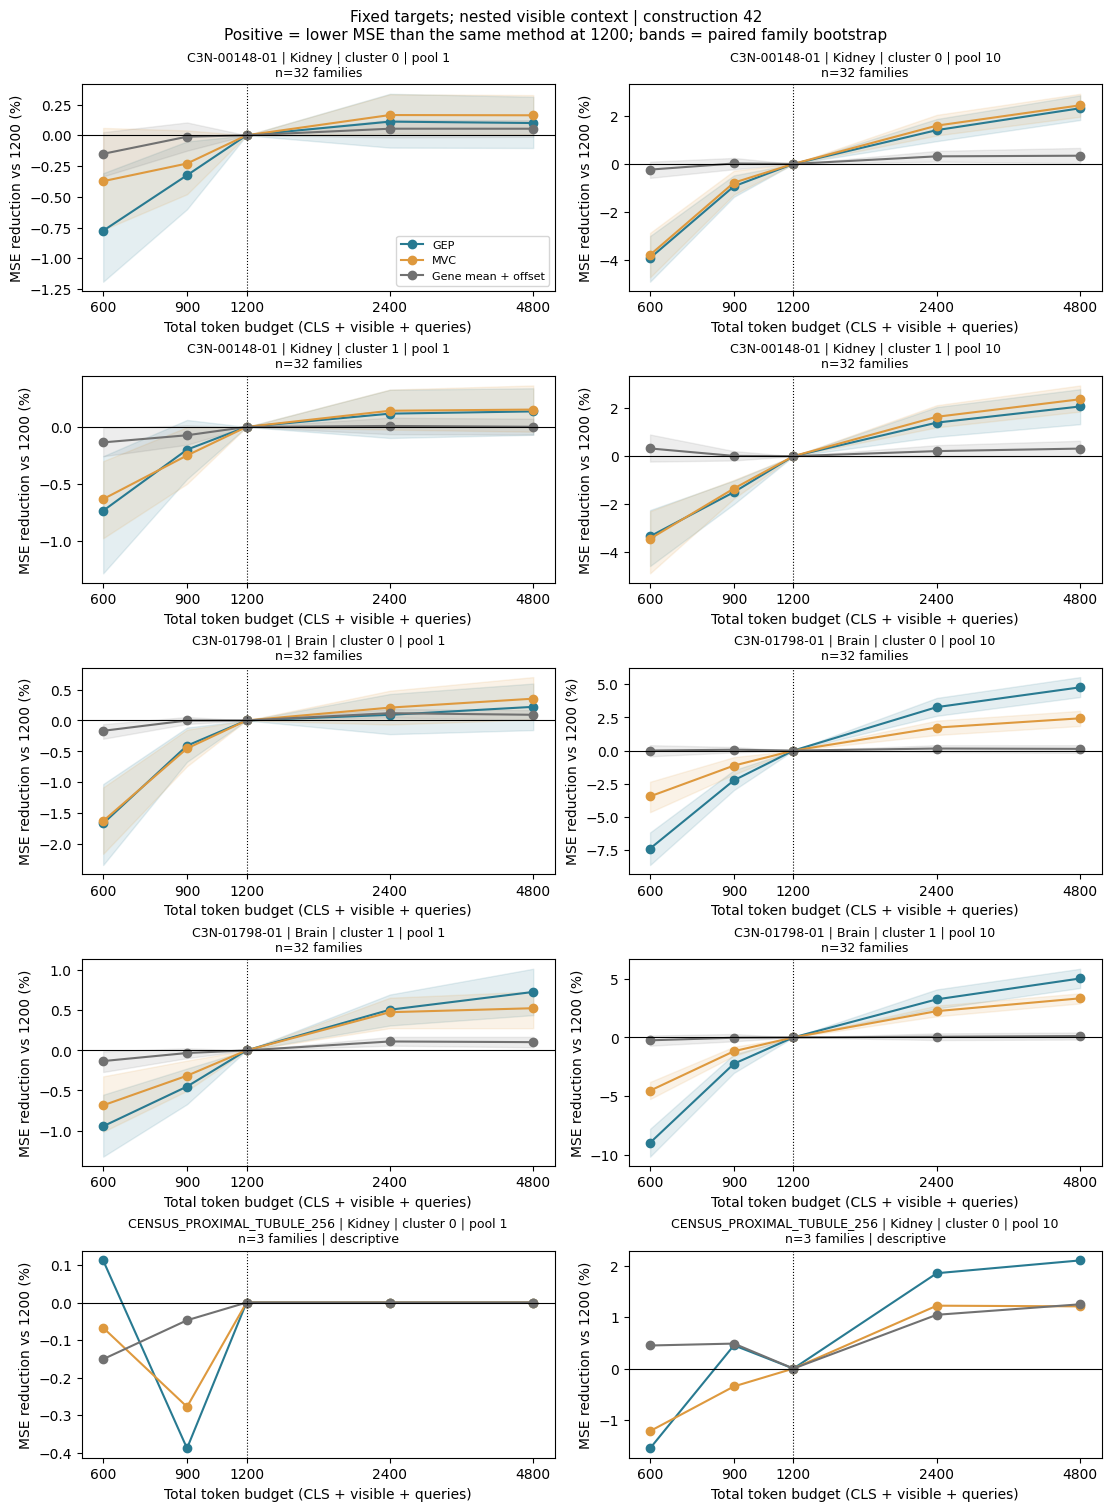

Saved results: /home/akash1/scgpt-cna/context_sweep/results/20261128T181334828041Z
Per-anchor-UMI results are in context_summary.csv; do not choose a method using the hidden true UMI group.


In [7]:
# 6 — Model-free scoring, paired contrasts and ONE context-response figure per construction.
import matplotlib.pyplot as plt
stamp=json.loads((RUN_DIR/'inference_complete.json').read_text())
assert stamp['run_signature']==sha(RUN_DIR/'run_manifest.json')
rows=[]; input_frames=[]; identity={}; identical_predictions={}
for stem in stamp['blocks']:
    d=RUN_DIR/'blocks'; path=d/(stem+'.csv.gz'); ip=d/(stem+'_inputs.csv')
    block_stamp=json.loads((d/(stem+'.complete.json')).read_text())
    assert block_stamp['run_signature']==stamp['run_signature']
    assert sha(path)==block_stamp['predictions_sha256'] and sha(ip)==block_stamp['inputs_sha256']
    q=pd.read_csv(path); block_inputs=pd.read_csv(ip); input_frames.append(block_inputs)
    for (unit,c,size,mask,family,length),part in q.groupby(
            ['unit_id','construction_seed','pool_size','mask_seed','family_id','context_budget'],sort=False):
        part=part.sort_values('gene_token')
        match=block_inputs.loc[block_inputs.family_id.eq(family)]
        assert len(match)==1
        ikey=(unit,c,size,mask,family,match.known_query_sha256.iloc[0])
        values=part[METHODS].to_numpy(float)
        if ikey in identical_predictions:
            np.testing.assert_allclose(values,identical_predictions[ikey],atol=2e-3,rtol=2e-4,err_msg='Identical inputs gave inconsistent predictions across budgets.')
        else: identical_predictions[ikey]=values
        key=(unit,c,size,mask,family)
        # Exact identities/target bins must be unchanged across all context conditions.
        snapshot=part[['gene_token','target_bin','anchor_umi','pooled_umi']].to_numpy()
        if key in identity: np.testing.assert_array_equal(snapshot,identity[key])
        else: identity[key]=snapshot
        groups=group_umi(part.anchor_umi.to_numpy())
        for group in GROUPS:
            sub=part if group=='all' else part.loc[groups==group]
            if sub.empty: continue
            y=sub.target_bin.to_numpy(float)
            for method in METHODS:
                err=sub[method].to_numpy(float)-y
                rows.append(dict(unit_id=unit,construction_seed=c,pool_size=size,mask_seed=mask,family_id=family,
                    context_budget=length,count_group=group,method=method,n_queries=len(y),
                    MSE=float(np.mean(err**2)),MAE=float(np.mean(abs(err))),signed_error=float(err.mean()),
                    target_variance=float(y.var())))
scores=pd.DataFrame(rows)
keys=['unit_id','construction_seed','pool_size','family_id','context_budget','count_group','method']
family=scores.groupby(keys,as_index=False).agg(MSE=('MSE','mean'),MAE=('MAE','mean'),
    signed_error=('signed_error','mean'),target_variance=('target_variance','mean'),n_masks=('mask_seed','nunique'))
# The same masks must contribute to each family's comparison at every length.
assert family.loc[family.count_group.eq('all'),'n_masks'].eq(len(MASK_SEEDS)).all()
mask_check=family.groupby(['unit_id','construction_seed','pool_size','family_id','count_group','method']).n_masks.nunique()
assert mask_check.eq(1).all(), 'Each subgroup must use the same available masks at every budget.'
join=['unit_id','construction_seed','pool_size','family_id','count_group','method']
ref=family.loc[family.context_budget.eq(REFERENCE_LENGTH),join+['MSE']].rename(columns={'MSE':'MSE_1200'})
family=family.merge(ref,on=join,validate='many_to_one')
family['gain_vs_1200']=family.MSE_1200-family.MSE
bkeys=[k for k in keys if k!='method']
b=family.loc[family.method.eq('gene_mean_plus_offset'),bkeys+['MSE']].rename(columns={'MSE':'baseline_MSE'})
family=family.merge(b,on=bkeys,validate='many_to_one')
family['gain_vs_baseline']=family.baseline_MSE-family.MSE
summary_rows=[]
cond=['unit_id','construction_seed','pool_size','context_budget','count_group','method']
for key,s in family.groupby(cond,sort=True):
    row=dict(zip(cond,key)); n=len(s)
    rng=np.random.default_rng(seed('paired-context-ci',*key))
    ix=rng.integers(0,n,size=(BOOTSTRAPS,n))
    delta=s.gain_vs_1200.to_numpy(); ref_mse=s.MSE_1200.to_numpy()
    draws=delta[ix].mean(axis=1)
    pct=100*draws/ref_mse[ix].mean(axis=1)
    row.update(n_families=n,mean_MSE=float(s.MSE.mean()),mean_MAE=float(s.MAE.mean()),
        MSE_1200=float(ref_mse.mean()),mean_gain_vs_1200=float(delta.mean()),
        gain_ci_low=float(np.quantile(draws,.025)),gain_ci_high=float(np.quantile(draws,.975)),
        percent_MSE_reduction_vs_1200=float(100*delta.mean()/ref_mse.mean()),
        percent_ci_low=float(np.quantile(pct,.025)),percent_ci_high=float(np.quantile(pct,.975)),
        baseline_MSE=float(s.baseline_MSE.mean()),mean_gain_vs_baseline=float(s.gain_vs_baseline.mean()),
        mean_target_variance=float(s.target_variance.mean()),mean_signed_error=float(s.signed_error.mean()))
    row['interval_status']='descriptive_small_n' if n<16 else 'conditional_family_bootstrap'
    summary_rows.append(row)
summary=pd.DataFrame(summary_rows).merge(units,on='unit_id',validate='many_to_one')
inputs=pd.concat(input_frames,ignore_index=True)
assert not inputs.duplicated(['unit_id','construction_seed','pool_size','family_id','mask_seed','context_budget']).any()
coverage_family=inputs.groupby(['unit_id','construction_seed','pool_size','context_budget','family_id'],as_index=False).agg(
    n_visible=('n_visible','mean'),n_detected=('n_detected','mean'),n_queries=('n_queries','mean'),
    actual_tokens=('actual_tokens','mean'),visible_fraction=('visible_fraction','mean'),saturated=('saturated','mean'))
coverage_summary=coverage_family.groupby(['unit_id','construction_seed','pool_size','context_budget'],as_index=False).agg(
    n_families=('family_id','nunique'),median_detected=('n_detected','median'),median_visible=('n_visible','median'),
    median_queries=('n_queries','median'),median_actual_tokens=('actual_tokens','median'),
    median_visible_fraction=('visible_fraction','median'),fraction_saturated=('saturated','mean'))
# If two budgets yield the exact same inputs, predictions should match (FP32 tolerance).
saturation_checks=[]
for key,s in inputs.groupby(['unit_id','construction_seed','pool_size','family_id','mask_seed','known_query_sha256']):
    if len(s)<2:continue
    unit,c,size,fam,mask,_=key
    saturation_checks.append(dict(unit_id=unit,construction_seed=c,pool_size=size,family_id=fam,mask_seed=mask,
        identical_input_budgets=','.join(map(str,sorted(s.context_budget)))))
for name,frame in [('scores_by_mask',scores),('scores_by_family',family),('context_summary',summary),
                   ('inference_inputs',inputs),('coverage_summary',coverage_summary),
                   ('identical_input_conditions',pd.DataFrame(saturation_checks))]:
    frame.to_csv(RUN_DIR/(name+'.csv'),index=False)

# Main table: fixed-target paired differences. Positive is improvement over 1200.
columns=['sample_id','unit_id','construction_seed','pool_size','context_budget','method','n_families','mean_MSE',
    'mean_gain_vs_1200','gain_ci_low','gain_ci_high','percent_MSE_reduction_vs_1200',
    'mean_gain_vs_baseline','interval_status']
report=summary.loc[summary.count_group.eq('all'),columns]
report.to_csv(RUN_DIR/'report_context_table.csv',index=False)
display(report.round(3))
print('Coverage/saturation: a larger budget adds no information once all available visible genes are included.')
display(coverage_summary.round(3))

FIG=RUN_DIR/'figures'; FIG.mkdir(exist_ok=True)
colors={'GEP':'#287A91','MVC':'#DE993E','gene_mean_plus_offset':'#717171'}
for c in sorted(summary.construction_seed.unique()):
    fig,axes=plt.subplots(len(units),len(POOL_SIZES),figsize=(11,3.0*len(units)),squeeze=False,constrained_layout=True)
    for i,u in enumerate(units.to_dict('records')):
        for j,size in enumerate(POOL_SIZES):
            ax=axes[i,j]
            s=summary.loc[summary.unit_id.eq(u['unit_id'])&summary.construction_seed.eq(c)&summary.pool_size.eq(size)&summary.count_group.eq('all')]
            n=int(s.n_families.min())
            for method in METHODS:
                z=s.loc[s.method.eq(method)].sort_values('context_budget')
                ax.plot(z.context_budget,z.percent_MSE_reduction_vs_1200,'o-',color=colors[method],label=method.replace('gene_mean_plus_offset','Gene mean + offset'))
                if n>=16:
                    ax.fill_between(z.context_budget.to_numpy(),z.percent_ci_low.to_numpy(),z.percent_ci_high.to_numpy(),color=colors[method],alpha=.12)
            ax.axhline(0,color='black',lw=.8); ax.axvline(1200,color='black',lw=.8,ls=':')
            ax.set_xscale('log',base=2); ax.set_xticks(LENGTHS,labels=[str(v) for v in LENGTHS])
            title=f"{u['sample_id']} | {u.get('tissue','')} | cluster {u.get('cluster','')} | pool {size}\nn={n} families"
            if n<16:title+=' | descriptive'
            ax.set_title(title,fontsize=9)
            ax.set_xlabel('Total token budget (CLS + visible + queries)')
            ax.set_ylabel('MSE reduction vs 1200 (%)')
    axes[0,0].legend(fontsize=8)
    fig.suptitle(f'Fixed targets; nested visible context | construction {c}\nPositive = lower MSE than the same method at 1200; bands = paired family bootstrap',fontsize=11)
    fig.savefig(FIG/f'context_response_seed{c}.png',dpi=220,bbox_inches='tight')
    fig.savefig(FIG/f'context_response_seed{c}.pdf',bbox_inches='tight')
    plt.show(); plt.close(fig)
print('Saved results:',RUN_DIR)
print('Per-anchor-UMI results are in context_summary.csv; do not choose a method using the hidden true UMI group.')


In [9]:
# 7 — Reopen SAVED results without loading model weights or the parent matrices.
# Run this cell, then cell 6. No inference is repeated.
from pathlib import Path
import hashlib,json
import numpy as np
import pandas as pd
from IPython.display import display
RUN_DIR=Path('/home/akash1/scgpt-cna/census_expression/results/20261110T170724523313Z_full')
m=json.loads((RUN_DIR/'run_manifest.json').read_text())
POOL_SIZES=m['POOL_SIZES']; LENGTHS=m['LENGTHS']; REFERENCE_LENGTH=m['REFERENCE_LENGTH']; BOOTSTRAPS=m['BOOTSTRAPS']
units=pd.read_csv(RUN_DIR/'evaluation_units.csv',dtype={'cluster':str})
# The mask count is recorded explicitly in the saved predictions, so reload it without the parent run.
complete=json.loads((RUN_DIR/'inference_complete.json').read_text())
MASK_SEEDS=sorted({int(stem.split('_mask')[1].split('_')[0]) for stem in complete['blocks']})
METHODS=['GEP','MVC','gene_mean_plus_offset']; GROUPS=['all','1 UMI','2–4 UMIs','5+ UMIs']
def seed(*parts):return int(hashlib.sha256('|'.join(map(str,parts)).encode()).hexdigest()[:16],16)
def sha(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for b in iter(lambda:f.read(8*1024**2),b''):h.update(b)
    return h.hexdigest()
def group_umi(x):return np.select([x==1,x<=4],['1 UMI','2–4 UMIs'],default='5+ UMIs')
print('Loaded:',RUN_DIR,'| now run cell 6.')


KeyError: 'POOL_SIZES'